# FDI Machine Learning — MARIDA (DPWMS / GEDH Module 1)

Guinea Environmental Data Hub · `plasticwaste_tool/marida_tool/`

Guinea's marine layer flags a water pixel when its Floating Debris Index (FDI) and NDVI both exceed
**mean + 3σ** of the local water population (Digital Earth Africa's rule). No labelled marine debris
exists for Guinea, so the rule cannot be checked against local labels.

MARIDA makes the question answerable. It is the only pixel-level marine-debris benchmark for
Sentinel-2, and — more useful than its debris class — it separately labels **Sargassum, natural organic
material, foam, ships, wakes, turbid water and sediment plumes**: the things that float on tropical
Atlantic water and look anomalous in the near-infrared.

This notebook answers four questions, in order:

1. **What does the FDI rule fire on?** (§2) — mostly floating material that is not debris:
   Sargassum, ships and foam. Annotated debris is 11% of its detections.
2. **Does a classifier separate debris from that material?** (§3) — yes: at the rule's own recall it
   lifts precision from 0.11 to 0.91, removing ship, Sargassum and foam detections almost entirely.
3. **What does the published layer — the rule, then the classifier — achieve?** (§4) — precision 0.90
   on MARIDA's test pixels and 0.92 on geographically unseen tiles.
4. **Does the classifier transfer to Guinea?** (§5–§9) — the features it uses at Conakry lie inside
   the range it was trained on; local checks and their limits are in §8–§9.

> Kikaki, K., Kakogeorgiou, I., Mikeli, P., Raitsos, D.E. & Karantzalos, K. (2022). MARIDA: A
> benchmark for Marine Debris detection from Sentinel-2 remote sensing data. *PLoS ONE* 17(1):
> e0262247. doi:10.5281/zenodo.5151941

**Runtime**: ~8 minutes after the one-off 1.16 GB download. No Earth Engine call is made except in §7
when the single-date results are missing — everything else reads the Conakry composite already cached
by `plasticwaste_analysis.ipynb`.

> **FDI definition.** The FDI follows Biermann et al. (2020, eq. 1–2): NIR = **B8**, RE2 = **B6**,
> SWIR1 = **B11**, with the **B4 (red)** wavelength in the interpolation ratio, pinned by
> `plasticwaste_tool/test_fdi_formula.py`. MARIDA ships every Sentinel-2 band, B06 included. Figures
> from the version before October 2026 (B8A in place of B6, no classifier in the published layer) are
> not comparable with the figures here.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from plasticwaste_tool import figstyle as FS
from plasticwaste_tool.marida_tool import baseline as B
from plasticwaste_tool.marida_tool import data as D
from plasticwaste_tool.marida_tool import domain as DOM
from plasticwaste_tool.marida_tool import evaluate as E
from plasticwaste_tool.marida_tool import features as F
from plasticwaste_tool.marida_tool import model as M

FS.use()
RUNS = ROOT / "plasticwaste_tool" / "manual_qa" / "runs" / "marida"
RUNS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 175)
print("ready")

ready


## 1. The data, and the split that matters

MARIDA ships an official train/val/test split, used here unmodified.
Re-splitting randomly would leak: patches from one scene share atmosphere, sun
geometry and often the same physical debris field, so a random pixel split
reports accuracy that does not survive contact with a new scene.

**But the official split has a subtler problem that must be measured before
any number from it is believed.** It splits by *patch*, and patches from the
same MGRS tile — the same place, imaged on different dates — land on both
sides. A model can then recognise a location rather than a material.

The cell below quantifies that. It is the reason every headline result in this
notebook is reported twice: once on the full test set, and once on the
geographically unseen tiles only.

In [2]:
Xtr, ytr, ptr = D.load_pixels("train")
Xte, yte, pte = D.load_pixels("test")

tile_tr = {D.normalise_id(p).split("_")[2] for p in ptr}
tile_te = np.array([D.normalise_id(p).split("_")[2] for p in pte])
scene_te = np.array([p.rsplit("_", 1)[0] for p in pte])
unseen = ~np.isin(tile_te, list(tile_tr))

print(f"train {len(ytr):,} px   test {len(yte):,} px")
print(f"debris: {int((ytr == 1).sum()):,} train, {int((yte == 1).sum()):,} test "
      f"({(yte == 1).mean():.3%} of test pixels)\n")

scn_tr = {D.normalise_id(p).rsplit('_', 1)[0] for p in ptr}
scn_te = {D.normalise_id(p).rsplit('_', 1)[0] for p in pte}
print(f"scenes shared between train and test: {len(scn_tr & scn_te)}  (good)")
print(f"MGRS TILES shared: {len(tile_tr & set(tile_te))} "
      f"-> {sorted(tile_tr & set(tile_te))}")
print(f"test pixels on a tile ALSO SEEN IN TRAINING: {(~unseen).mean():.0%}")
print(f"geographically unseen tiles: {sorted(set(tile_te[unseen]))}, "
      f"{int(unseen.sum()):,} px, {int(((yte == 1) & unseen).sum())} debris px")

display(D.class_counts(ytr))

train 429,412 px   test 194,863 px
debris: 1,943 train, 381 test (0.196% of test pixels)

scenes shared between train and test: 0  (good)
MGRS TILES shared: 6 -> ['16PCC', '16PDC', '16PEC', '16QED', '18QYF', '48PZC']
test pixels on a tile ALSO SEEN IN TRAINING: 99%
geographically unseen tiles: ['50LLR', '51PTS'], 2,045 px, 79 debris px


,code,class,pixels,share,role
7,8,Sediment-Laden Water,154335,0.359410,water background
6,7,Marine Water,86877,0.202316,water background
9,10,Turbid Water,86820,0.202183,water background
5,6,Clouds,65295,0.152057,other
10,11,Shallow Water,13852,0.032258,water background
12,13,Cloud Shadows,5675,0.013216,other
13,14,Wakes,4974,0.011583,floating confuser
4,5,Ship,3289,0.007659,floating confuser
11,12,Waves,2975,0.006928,other
0,1,Marine Debris,1943,0.004525,TARGET


### Reading that class table

Marine Debris is **0.45%** of the training pixels. Three consequences follow,
and they shape everything downstream:

- **Accuracy is never reported in this notebook.** Predicting "not debris"
  everywhere scores over 99%.
- **The confuser classes are individually tiny** — Foam 469 pixels, Natural
  Organic Material 723. Per-class rates on them carry real sampling error, and
  the bootstrap in §3 is there because of it.
- **The water classes dominate** (76% of pixels). That is appropriate: water
  is the background an anomaly threshold is estimated against, and it is what
  the rule must not fire on.

## 2. What does the FDI rule fire on?

This section evaluates the **FDI arm** of the deployed rule on its own — FDI above mean + 3σ of the
scene's water pixels — because that is the part that responds to floating material. The NDVI arm and
the classifier are added in §4.

The rule is not a reimplementation: `marida_tool.features.fdi` calls `fdi_tool.spectral.compute_fdi`,
the deployed function, so this evaluation follows the shipped formula automatically.

The threshold is derived **per scene**, exactly as the pipeline derives one per AOI, and is not tuned
to MARIDA. Fitting it would answer how well the rule *could* do; what matters is how well it *does*.

In [3]:
r = B.predict(Xte, yte, group=scene_te)
fired = B.what_does_it_fire_on(yte, r["pred"])
display(fired[fired.flagged > 0])

s = B.binary_scores(yte, r["pred"], r["scored"])
print(f"precision {s['precision']:.3f}   recall {s['recall']:.3f}   "
      f"F1 {s['f1']:.3f}")
print(f"base rate {s['base_rate']:.4%}   lift {s['lift']:.0f}x\n")

conf = fired[fired.role == "floating confuser"]["share_of_all_detections"].sum()
water = fired[fired.role == "water background"]["share_of_all_detections"].sum()
print(f"Of every 100 pixels the rule flags on MARIDA:")
print(f"   {fired[fired.role == 'TARGET']['share_of_all_detections'].iloc[0]*100:4.0f} are annotated Marine Debris")
print(f"   {conf*100:4.0f} are other FLOATING material (ships, wakes, foam, Sargassum)")
print(f"   {water*100:4.0f} are plain water -- false alarms against the background")

,code,class,pixels,flagged,recall_within_class,share_of_all_detections,role
2,3,Sparse Sargassum,881,718,0.814983,0.317699,floating confuser
4,5,Ship,1174,392,0.333901,0.173451,floating confuser
1,2,Dense Sargassum,760,376,0.494737,0.166372,floating confuser
0,1,Marine Debris,381,239,0.627297,0.105752,TARGET
8,9,Foam,387,205,0.529716,0.090708,floating confuser
13,14,Wakes,1570,121,0.077070,0.053540,floating confuser
10,11,Shallow Water,2506,68,0.027135,0.030088,water background
9,10,Turbid Water,32226,61,0.001893,0.026991,water background
3,4,Natural Organic Material,49,45,0.918367,0.019912,floating confuser
7,8,Sediment-Laden Water,93037,20,0.000215,0.008850,water background


precision 0.106   recall 0.627   F1 0.181
base rate 0.2434%   lift 43x

Of every 100 pixels the rule flags on MARIDA:
     11 are annotated Marine Debris
     82 are other FLOATING material (ships, wakes, foam, Sargassum)
      7 are plain water -- false alarms against the background


### The finding, stated plainly

**Most of what the FDI rule flags is floating material that is not debris.** Sparse Sargassum is the
largest category (32% of detections), then ships (17%) and dense Sargassum (17%); annotated marine
debris is 11%, foam 9%, wakes 5%. Of every 100 flagged pixels, 11 are debris, 82 are other floating
material and 7 are plain water.

The rule is nonetheless informative: debris is **43 times** more concentrated among flagged pixels
than in the test set at large, with no training data required. But on its own it counts *anomalous
floating material*, not debris — which is why the published layer passes its detections through a
classifier (§4).

saved  manual_qa\figures\marida_01_what_the_rule_fires_on.png
caption: Composition of the mean+3sigma FDI rule's detections on the MARIDA test set. The largest single category is Sparse Sargassum (32% of detections); annotated marine debris is 11%, and 82% is floating material other than debris. The rule concentrates debris 43-fold over the water background, so it is informative, but on its own it counts anomalous floating material, not plastic -- which is why the published layer passes its detections through the classifier (section 4).


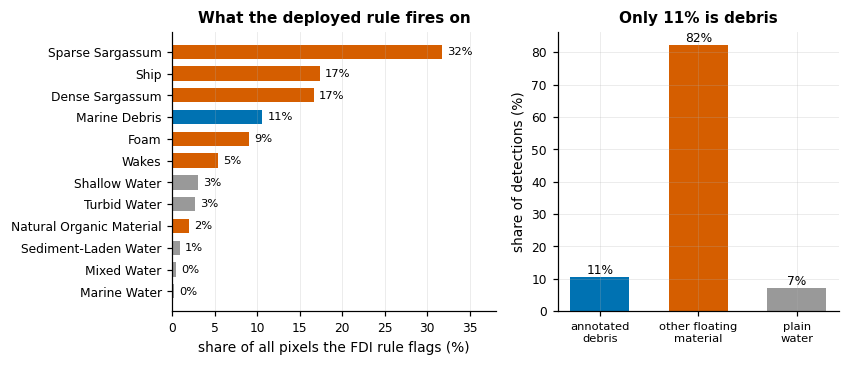

In [4]:
fig, axes = FS.plt.subplots(1, 2, figsize=(7.8, 3.4),
                            gridspec_kw={"width_ratios": [1.15, 1]})

d = fired[fired.flagged > 0].sort_values("share_of_all_detections")
cmap = {"TARGET": FS.OKABE_ITO["blue"],
        "floating confuser": FS.OKABE_ITO["vermillion"],
        "water background": FS.OKABE_ITO["grey"],
        "other": FS.OKABE_ITO["yellow"]}
ax = axes[0]
ax.barh(d["class"], d["share_of_all_detections"] * 100,
        color=[cmap[x] for x in d["role"]], height=0.66)
for i, v in enumerate(d["share_of_all_detections"] * 100):
    ax.text(v + 0.6, i, f"{v:.0f}%", va="center", fontsize=7.5)
ax.set_xlabel("share of all pixels the FDI rule flags (%)")
ax.set_title("What the deployed rule fires on")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, d["share_of_all_detections"].max() * 100 * 1.2)

ax = axes[1]
grp = d.groupby("role")["share_of_all_detections"].sum().reindex(
    ["TARGET", "floating confuser", "water background", "other"]).dropna()
ax.bar(range(len(grp)), grp * 100, color=[cmap[x] for x in grp.index], width=0.6)
ax.set_xticks(range(len(grp)))
ax.set_xticklabels(["annotated\ndebris", "other floating\nmaterial",
                    "plain\nwater", "other"][:len(grp)], fontsize=7.5)
ax.set_ylabel("share of detections (%)")
ax.set_title(f"Only {grp.get('TARGET', 0)*100:.0f}% is debris")
for i, v in enumerate(grp * 100):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=8)

fig.tight_layout()
_s = B.binary_scores(yte, r["pred"], r["scored"])
_top = d.iloc[-1]
FS.save(fig, "marida_01_what_the_rule_fires_on",
        f"Composition of the mean+3sigma FDI rule's detections on the MARIDA "
        f"test set. The largest single category is {_top['class']} "
        f"({_top['share_of_all_detections']:.0%} of detections); annotated marine "
        f"debris is {grp.get('TARGET', 0):.0%}, and "
        f"{grp.get('floating confuser', 0):.0%} is floating material other than "
        f"debris. The rule concentrates debris {_s['lift']:.0f}-fold over the "
        f"water background, so it is informative, but on its own it counts "
        f"anomalous floating material, not plastic -- which is why the published "
        f"layer passes its detections through the classifier (section 4).")
FS.plt.show()

## 3. Does a classifier separate debris from that material?

A random forest (debris vs everything else) is fitted on MARIDA's training split in two versions:

- **full** — all 11 MARIDA bands plus 6 indices (17 features).
- **pipeline** — only the seven bands Guinea's fetch downloads (B3, B4, B6, B8, B8A, B11, B12) plus
  the five indices derivable from them (12 features). This is the one the platform uses, so it costs
  **no extra imagery**.

Comparison is at **matched recall**: the forest's probability cut is moved until it finds the same
fraction of true debris the rule finds, and the two are then compared on precision. Comparing at the
forest's default 0.5 cut would compare two arbitrary operating points.

ROC-AUC is reported alongside because it is prevalence-invariant. Debris prevalence in Guinea is unknown
and certainly differs from MARIDA's; precision does not transfer across prevalence, AUC does.

In [5]:
from sklearn.ensemble import RandomForestClassifier

Ftr, Fte = F.build(Xtr), F.build(Xte)
all_cols = list(Ftr.columns)

fits = {}
for label, cols in [("full", all_cols), ("pipeline", DOM.PIPELINE_FEATURES)]:
    clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                 class_weight="balanced_subsample",
                                 n_jobs=-1, random_state=M.SEED)
    clf.fit(Ftr[cols].values, (ytr == 1).astype(int))
    sc = clf.predict_proba(Fte[cols].values)[:, list(clf.classes_).index(1)]
    fits[label] = {"clf": clf, "cols": cols, "score": sc}

rows = []
for label, f in fits.items():
    for tag, mask in [("all test", r["scored"]),
                      ("unseen locations", r["scored"] & unseen)]:
        c = E.compare_at_matched_recall((yte == 1), r["pred"], f["score"], mask)
        rows.append({"model": label, "n_features": len(f["cols"]),
                     "evaluated_on": tag, "n_px": c["n_scored"],
                     "debris_px": c["n_debris"], "base_rate": c["base_rate"],
                     "rule_precision": c["rule_precision"],
                     "model_precision": c["model_precision"],
                     "precision_ratio": c["precision_ratio"],
                     "rule_FP": c["rule_false_positives"],
                     "model_FP": c["model_false_positives"],
                     "model_ROC_AUC": c["model_roc_auc"]})
display(pd.DataFrame(rows))

print("The pipeline model matches the full model. The improvement therefore")
print("requires NO change to what the Guinea fetch downloads.")

,model,n_features,evaluated_on,n_px,debris_px,base_rate,rule_precision,model_precision,precision_ratio,rule_FP,model_FP,model_ROC_AUC
0,full,17,all test,156506,381,0.002434,0.105752,0.919231,8.692308,2021,21,0.999370
1,full,17,unseen locations,802,79,0.098504,0.322034,0.873563,2.712644,160,11,0.997776
2,pipeline,12,all test,156506,381,0.002434,0.105752,0.908745,8.593156,2021,24,0.997336
3,pipeline,12,unseen locations,802,79,0.098504,0.322034,0.873563,2.712644,160,11,0.996253


The pipeline model matches the full model. The improvement therefore
requires NO change to what the Guinea fetch downloads.


### The held-out-location result rests on 79 debris pixels

That is few enough that the comparison needs an interval, and the interval
must be built by resampling **patches**, not pixels: pixels within a patch are
spatially autocorrelated, so a pixel bootstrap would treat one debris field as
if it were hundreds of independent observations and produce a confidence
interval far too narrow.

In [6]:
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(M.SEED)
mask = r["scored"] & unseen
t, sc, rp, grp = (yte == 1)[mask], fits["pipeline"]["score"][mask], \
                 r["pred"][mask], pte[mask]
patches = np.unique(grp)
where = {p: np.flatnonzero(grp == p) for p in patches}

aucs, ratios = [], []
for _ in range(2000):
    idx = np.concatenate([where[p] for p in
                          rng.choice(patches, len(patches), replace=True)])
    tt, ss, rr = t[idx], sc[idx], rp[idx]
    if tt.sum() == 0 or tt.all():
        continue
    aucs.append(roc_auc_score(tt, ss))
    rtp, rfp = int((tt & rr).sum()), int((~tt & rr).sum())
    if not (rtp + rfp):
        continue
    rprec, rrec = rtp / (rtp + rfp), rtp / tt.sum()
    mp = ss >= M.threshold_for_recall(tt, ss, rrec)
    mtp, mfp = int((tt & mp).sum()), int((~tt & mp).sum())
    if rprec > 0 and (mtp + mfp):
        ratios.append((mtp / (mtp + mfp)) / rprec)

print(f"patch-level bootstrap, {len(patches)} patches, {int(t.sum())} debris px")
print(f"  ROC-AUC         {np.median(aucs):.4f}  "
      f"90% CI [{np.quantile(aucs, .05):.4f}, {np.quantile(aucs, .95):.4f}]")
print(f"  precision gain  {np.median(ratios):.2f}x  "
      f"90% CI [{np.quantile(ratios, .05):.2f}, {np.quantile(ratios, .95):.2f}]")
print(f"  favours the model in {np.mean(np.array(ratios) > 1):.0%} of draws")

patch-level bootstrap, 30 patches, 79 debris px
  ROC-AUC         0.9965  90% CI [0.9928, 0.9992]
  precision gain  2.63x  90% CI [1.56, 4.78]
  favours the model in 100% of draws


,code,class,pixels,role,rule_flagged,rule_rate,model_flagged,model_rate,change
2,3,Sparse Sargassum,881,floating confuser,718,0.814983,0,0.000000,-718
4,5,Ship,1174,floating confuser,392,0.333901,9,0.007666,-383
1,2,Dense Sargassum,760,floating confuser,376,0.494737,0,0.000000,-376
0,1,Marine Debris,381,TARGET,239,0.627297,239,0.627297,0
7,9,Foam,387,floating confuser,205,0.529716,0,0.000000,-205
10,14,Wakes,1570,floating confuser,121,0.077070,8,0.005096,-113
9,11,Shallow Water,2506,water background,68,0.027135,0,0.000000,-68
8,10,Turbid Water,32226,water background,61,0.001893,0,0.000000,-61
3,4,Natural Organic Material,49,floating confuser,45,0.918367,6,0.122449,-39
6,8,Sediment-Laden Water,93037,water background,20,0.000215,0,0.000000,-20


saved  manual_qa\figures\marida_02_confusions_removed.png
caption: Pixels flagged by the FDI rule and by the classifier at identical recall on the MARIDA test set. Debris detections are unchanged by construction; ship detections fall from 392 to 9, Sargassum from 1094 to 0 and foam from 205 to 0. The gain is the removal of specific, nameable confusions rather than an abstract improvement in score.


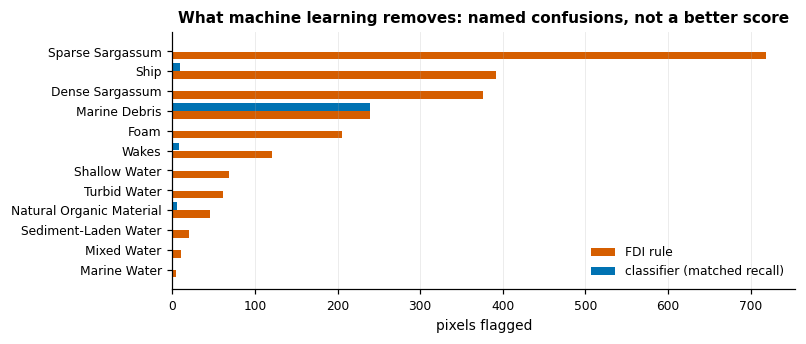

,feature,importance
0,FAI,0.185941
1,FDI,0.144797
2,NDVI,0.122251
3,PI,0.111040
4,NDWI,0.089192
5,B01,0.067717
6,B05,0.050119
7,B12,0.042626


Leading features: FAI, FDI, NDVI, PI.
The model keys on whether floating material is CHLOROPHYLL-BEARING,
which is exactly the physics that separates Sargassum from debris,
and is a reassuring check that it is not keying on brightness alone.


In [7]:
cut = E.compare_at_matched_recall(
    (yte == 1), r["pred"], fits["pipeline"]["score"],
    r["scored"])["model_cut_at_matched_recall"]
cb = E.confuser_breakdown(yte, r["pred"], fits["pipeline"]["score"], cut,
                          r["scored"])
cb = cb[(cb.rule_flagged + cb.model_flagged) > 0]
display(cb)

fig, ax = FS.plt.subplots(figsize=(7.4, 3.2))
d = cb.sort_values("rule_flagged")
yy = np.arange(len(d))
ax.barh(yy - 0.2, d["rule_flagged"], height=0.38,
        color=FS.OKABE_ITO["vermillion"], label="FDI rule")
ax.barh(yy + 0.2, d["model_flagged"], height=0.38,
        color=FS.OKABE_ITO["blue"], label="classifier (matched recall)")
ax.set_yticks(yy); ax.set_yticklabels(d["class"], fontsize=8)
ax.set_xlabel("pixels flagged")
ax.set_title("What machine learning removes: named confusions, not a better score")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
fig.tight_layout()
def _n(cls, col):
    return int(cb.loc[cb["class"].isin(cls), col].sum())
_ship, _sarg, _foam = ["Ship"], ["Dense Sargassum", "Sparse Sargassum"], ["Foam"]
FS.save(fig, "marida_02_confusions_removed",
        f"Pixels flagged by the FDI rule and by the classifier at identical "
        f"recall on the MARIDA test set. Debris detections are unchanged by "
        f"construction; ship detections fall from {_n(_ship, 'rule_flagged')} to "
        f"{_n(_ship, 'model_flagged')}, Sargassum from {_n(_sarg, 'rule_flagged')} "
        f"to {_n(_sarg, 'model_flagged')} and foam from {_n(_foam, 'rule_flagged')} "
        f"to {_n(_foam, 'model_flagged')}. The gain is the removal of specific, "
        f"nameable confusions rather than an abstract improvement in score.")
FS.plt.show()

_imp = M.importances(fits["full"]["clf"], all_cols)
display(_imp.head(8))
print(f"Leading features: {', '.join(_imp['feature'].head(4))}.")
print("The model keys on whether floating material is CHLOROPHYLL-BEARING,")
print("which is exactly the physics that separates Sargassum from debris,")
print("and is a reassuring check that it is not keying on brightness alone.")

### Reading the classifier result

At the rule's own recall, the pipeline model lifts precision from **0.11 to 0.91** on all test pixels
and from **0.32 to 0.87** on the geographically unseen tiles — a **2.6× gain, 90% CI [1.6, 4.8],
favouring the model in 100% of patch-level bootstrap draws**. ROC-AUC is 0.997. The pipeline model
matches the full model, so nothing beyond the bands Guinea already downloads is needed.

The gain is the removal of nameable confusions: ship detections fall from 392 to 9, Sargassum from
1,094 to 0, foam from 205 to 0, wakes from 121 to 8. The leading features are FAI, FDI, NDVI and PI —
whether the floating material bears chlorophyll, which is the physics that separates Sargassum from
debris — not brightness alone.

## 4. The published layer: the rule, then the classifier

The platform publishes the two in sequence, as Biermann et al. (2020) do — they separate debris from
vegetation and seaweed with a classifier trained on labelled spectra, not with a threshold:

1. the mean+3σ rule on **FDI and NDVI** over the whole water population (Digital Earth Africa);
2. the MARIDA classifier on the rule's detections, keeping a pixel where P(Marine Debris) ≥ 0.5 — the
   binary classifier's own decision boundary, not a value tuned to Guinea.

`39_freeze_debris_filter.py` trains that classifier once on MARIDA's training split (the twelve pipeline
features, the settings of §3), measures the sequence on MARIDA's test split, and saves the model inside
the package (`fdi_tool/models/debris_filter.joblib`) so a workstation and the backend container load the
same file. The table also shows the FDI arm alone (§2) followed by the same classifier, for comparison.

In [8]:
import subprocess

p = subprocess.run([sys.executable, "39_freeze_debris_filter.py"],
                   cwd=ROOT / "plasticwaste_tool", capture_output=True, text=True)
print(p.stdout[-3000:])
if p.returncode:
    print("STDERR:", p.stderr[-3000:])

meta = json.loads((ROOT / "plasticwaste_tool" / "fdi_tool" / "models" /
                   "debris_filter_meta.json").read_text(encoding="utf-8"))
rows = []
for tag, name in (("all_test", "all test pixels"), ("unseen_tiles", "geographically unseen tiles")):
    for stage, label in (("rule", "FDI-and-NDVI rule (deployed)"),
                         ("rule_then_classifier", "  then classifier (published)"),
                         ("fdi_rule", "FDI rule alone (section 2)"),
                         ("fdi_rule_then_classifier", "  then classifier")):
        s = meta["metrics_marida_test"][tag][stage]
        rows.append({"evaluated on": name, "detector": label,
                     "flagged px": s["tp"] + s["fp"], "precision": s["precision"],
                     "recall": s["recall"], "lift": s["lift"]})
display(pd.DataFrame(rows).set_index(["evaluated on", "detector"]).round(3))
print("what the published layer keeps on MARIDA:")
display(pd.DataFrame(meta["metrics_marida_test"]["composition"]["rule_then_classifier"]))

loading MARIDA ...
training: 429,412 px, 1,943 debris, 400 trees, min_samples_leaf 2 ...
  40s

MARIDA test split (classifier keeps P >= 0.5):
  all_test      FDI-and-NDVI rule (deployed)    precision 0.076  recall 0.247  (1,243 px)
  all_test        then classifier (published)   precision 0.895  recall 0.247  (105 px)
  all_test      FDI rule alone                  precision 0.106  recall 0.627  (2,260 px)
  all_test        then classifier               precision 0.808  recall 0.551  (260 px)
  unseen_tiles  FDI-and-NDVI rule (deployed)    precision 0.654  recall 0.886  (107 px)
  unseen_tiles    then classifier (published)   precision 0.921  recall 0.886  (76 px)
  unseen_tiles  FDI rule alone                  precision 0.322  recall 0.962  (236 px)
  unseen_tiles    then classifier               precision 0.892  recall 0.937  (83 px)

  what the published layer keeps:
    Marine Debris               89.5%  (94 px)
    Ship                         4.8%  (5 px)
    Natural Organic Mat

flagged px  precision  recall     lift
evaluated on                detector                                                             
all test pixels             FDI-and-NDVI rule (deployed)         1243      0.076   0.247   31.064
                              then classifier (published)         105      0.895   0.247  367.743
                            FDI rule alone (section 2)           2260      0.106   0.627   43.441
                              then classifier                     260      0.808   0.551  331.781
geographically unseen tiles FDI-and-NDVI rule (deployed)          107      0.654   0.886    6.641
                              then classifier (published)          76      0.921   0.886    9.350
                            FDI rule alone (section 2)            236      0.322   0.962    3.269
                              then classifier                      83      0.892   0.937    9.051

what the published layer keeps on MARIDA:


,class,flagged,share
0,Marine Debris,94,0.8952
1,Ship,5,0.0476
2,Natural Organic Material,4,0.0381
3,Wakes,1,0.0095
4,Mixed Water,1,0.0095


### The same sequence on Guinean water

The Conakry January 2024 composite (cached by `plasticwaste_analysis.ipynb`) through
`pipeline.run_from_arrays` — the function the notebook, the national and river runs and the platform all
call. NDVI and distance to land describe what each stage keeps: open water has a median NDVI near −0.2;
plant canopy lies above about 0.5.

In [9]:
import os
from scipy import ndimage
from plasticwaste_tool import config as pwcfg, api_connector as api, data_loader as DL
from plasticwaste_tool.fdi_tool import pipeline as PIPE

CACHE_R = Path(os.environ.get("PW_RASTER_CACHE")
               or Path(pwcfg.PROCESSING_CONFIG["cache_dir"]) / "rasters")
stem = f"conakry_{api.aoi_cache_token('conakry')}_2024-01-01_2024-02-01_composite"
cb, cprof = DL.read_composite(str(CACHE_R / f"{stem}.tif"))
cres = PIPE.run_from_arrays(cb, cprof, "2024-01-01")

cwater = np.nan_to_num(cb["WATER"], nan=0.0) > 0
cdist = ndimage.distance_transform_edt(cwater)
rows = []
for label, m in (("rule alone", cres["hotspot_binary_rule"]),
                 ("rule, then classifier", cres["hotspot_binary"])):
    nd = cres["ndvi"][m]
    rows.append({"detector": label, "pixels": int(m.sum()),
                 "median NDVI": float(np.median(nd)) if nd.size else np.nan,
                 "share NDVI > 0.5": float((nd > 0.5).mean()) if nd.size else np.nan,
                 "share within 20 m of land": float((cdist[m] <= 1).mean()) if nd.size else np.nan})
display(pd.DataFrame(rows).set_index("detector").round(3))
print(f"published patches: {cres['summary']['n_patches']}, "
      f"{cres['summary']['total_area_ha']} ha")

,pixels,median NDVI,share NDVI > 0.5,share within 20 m of land
detector,,,,
rule alone,6558,0.473,0.463,0.826
"rule, then classifier",242,0.103,0.000,0.025


published patches: 26, 9.04 ha


### Reading the published-layer results

**On MARIDA**, the published layer reaches precision **0.90** (all test pixels) and **0.92**
(geographically unseen tiles). Recall is 0.25 and 0.89 respectively, and the classifier loses none of
the debris pixels the rule finds: recall is the same before and after it. The lower recall on all test
pixels comes from the NDVI arm of the rule. What the published layer keeps is 90% annotated debris; the
rest is a few ship, organic-material and wake pixels.

**At Conakry** the two stages behave as the benchmark predicts. The rule's 6,558 pixels have a median
NDVI of 0.47, almost half above 0.5, and 83% lie within 20 m of land: the NDVI arm, applied to the FDI as
Biermann et al. define it, selects vegetated shoreline. The classifier keeps 242 of them, with a median
NDVI of 0.10 and 2.5% within 20 m of land — **26 patches, 9.04 ha**.

## 5. Does the classifier transfer to Guinea?

Three differences between MARIDA and Guinea are known before looking at data, and each is checked:

**Atmospheric level.** Guinea uses `COPERNICUS/S2_SR_HARMONIZED` — Level-2A surface reflectance. If
MARIDA were Level-1C top-of-atmosphere, every band would carry an atmospheric path term the model had
learned as signal. Tested below rather than taken from documentation.

**Feature distributions.** A random forest cannot extrapolate: outside its training range it returns
whatever the nearest leaf held. Whether Conakry's pixels lie inside that range is measured in §5b.

**Temporal compositing.** MARIDA annotates single acquisitions; Guinea runs a monthly median. Tested in
§7.

MARIDA also contains no West African scene (it covers UTM zones 16–52; Guinea is zone 28, and one MARIDA
scene lies within two zones of it). No distributional check can remove that caveat.

In [10]:
import rasterio

print(json.dumps(DOM.is_atmospherically_corrected(Xtr), indent=1))
print("\n-> negative reflectances are impossible at top-of-atmosphere, so")
print("   MARIDA is atmospherically corrected. No TOA/BOA mismatch.\n")

import os
from plasticwaste_tool import config as pwcfg, api_connector as api
# The raster cache the FDI pipeline writes to (<APP_SCRATCH_DIR>/cache/rasters),
# and the composite named as pipeline.run_from_gee names it: the token carries
# the FDI formula id, so this is always the current definition's composite.
CACHE = Path(os.environ.get("PW_RASTER_CACHE")
             or Path(pwcfg.PROCESSING_CONFIG["cache_dir"]) / "rasters")
name = f"conakry_{api.aoi_cache_token('conakry')}_2024-01-01_2024-02-01_composite"
with rasterio.open(CACHE / f"{name}.tif") as s:
    arr = s.read().astype("float32"); bnames = list(s.descriptions)
with rasterio.open(CACHE / f"{name}_WATER.tif") as s:
    water = np.nan_to_num(s.read(1), nan=0.0) > 0

band = {n: arr[i] for i, n in enumerate(bnames)}
fdi = band["FDI"]
valid = water & np.isfinite(fdi) & np.isfinite(band["B8"])
thr = float(fdi[valid].mean() + 3 * fdi[valid].std())
flagged = valid & (fdi > thr)
print(f"Conakry: {int(valid.sum()):,} water px, threshold {thr:.5f}, "
      f"{int(flagged.sum()):,} flagged")

X_gn = np.zeros((int(flagged.sum()), len(D.BANDS)), dtype="float32")
for i, b in enumerate(D.BANDS):
    for cn, mn in DOM.COMPOSITE_TO_MARIDA.items():
        if mn == b and cn in band:
            X_gn[:, i] = band[cn][flagged]

bands_df = DOM.compare_water_populations(Xtr, ytr, band, valid)
display(bands_df)

{
 "min_reflectance": -0.008302144706249237,
 "fraction_with_negative_band": 0.0006986297541754772,
 "verdict": "atmospherically corrected (L2A-like)"
}

-> negative reflectances are impossible at top-of-atmosphere, so
   MARIDA is atmospherically corrected. No TOA/BOA mismatch.

Conakry: 4,524,646 water px, threshold 0.06804, 102,827 flagged


,band,marida_median,deploy_median,ratio,marida_p05,marida_p95,deploy_p95,deploy_outside_training_range,shift_flag
0,B03,0.063236,0.05480,0.866599,0.014584,0.118416,0.08335,0.0,ok
1,B04,0.042689,0.03625,0.849175,0.007238,0.156098,0.07465,0.0,ok
2,B06,0.033001,0.02830,0.857538,0.004919,0.121185,0.05285,0.0,ok
3,B08,0.030543,0.02445,0.800510,0.003953,0.108459,0.04670,0.0,ok
4,B8A,0.032908,0.02440,0.741469,0.004191,0.110179,0.04210,0.0,ok
5,B11,0.005994,0.01440,2.402561,0.001472,0.028751,0.02065,0.0,SHIFTED
6,B12,0.003956,0.01140,2.881488,0.000857,0.021464,0.01585,0.0,SHIFTED


In [11]:
fig, axes = FS.plt.subplots(1, 2, figsize=(7.8, 3.2),
                            gridspec_kw={"width_ratios": [1, 1.1]})

ax = axes[0]
xx = np.arange(len(bands_df))
ax.bar(xx - 0.2, bands_df["marida_median"], width=0.38,
       color=FS.OKABE_ITO["blue"], label="MARIDA (training)")
ax.bar(xx + 0.2, bands_df["deploy_median"], width=0.38,
       color=FS.OKABE_ITO["orange"], label="Conakry (deployment)")
ax.set_xticks(xx); ax.set_xticklabels(bands_df["band"], fontsize=8)
ax.set_ylabel("median reflectance, water pixels")
ax.set_title("Water background differs where it matters")
ax.legend(loc="upper right")

ax = axes[1]
cols = [FS.OKABE_ITO["vermillion"] if f == "SHIFTED" else FS.OKABE_ITO["grey"]
        for f in bands_df["shift_flag"]]
ax.bar(bands_df["band"], bands_df["ratio"], color=cols, width=0.6)
ax.axhline(1.0, color="black", linewidth=1.0)
ax.axhspan(0.67, 1.5, color=FS.OKABE_ITO["green"], alpha=0.12)
ax.set_ylabel("Conakry median / MARIDA median")
_sw = bands_df[bands_df["band"].isin(["B11", "B12"])]["ratio"]
_vn = bands_df[~bands_df["band"].isin(["B11", "B12"])]["ratio"]
ax.set_title(f"SWIR is {_sw.min():.1f}-{_sw.max():.1f}$\\times$ higher")
for i, v in enumerate(bands_df["ratio"]):
    ax.text(i, v + 0.06, f"{v:.2f}", ha="center", fontsize=7.5)
ax.set_ylim(0, bands_df["ratio"].max() * 1.25)

fig.tight_layout()
FS.save(fig, "marida_03_domain_shift",
        f"Water-pixel reflectance in MARIDA (training) against the Conakry "
        f"monthly composite (deployment). The visible, red-edge and NIR bands "
        f"agree to within {(1 - _vn).abs().max():.0%}, but SWIR runs "
        f"{_sw.min():.1f}-{_sw.max():.1f} times higher at Conakry, and the "
        f"Floating Debris Index anchors its baseline on SWIR. Shaded band marks "
        f"agreement within 50%.")
FS.plt.show()

saved  manual_qa\figures\marida_03_domain_shift.png
caption: Water-pixel reflectance in MARIDA (training) against the Conakry monthly composite (deployment). The visible, red-edge and NIR bands agree to within 26%, but SWIR runs 2.4-2.9 times higher at Conakry, and the Floating Debris Index anchors its baseline on SWIR. Shaded band marks agreement within 50%.


C:\Users\ASUS\AppData\Local\Temp\ipykernel_28712\1627340505.py:37: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
  FS.plt.show()


### 5b. Comparing like with like: flagged pixels against flagged pixels

The SWIR ratios above (B11 2.4×, B12 2.9×) look large, but a ratio is the wrong unit for a tree
ensemble. Over water, SWIR reflectance is a small number, and MARIDA's own spread is wide enough that a
2.4× higher median can still sit well inside the training range. What governs a random forest is
whether deployment pixels fall *outside* the range it was fitted on, measured in units of the training
spread.

The comparison must also be like for like. The classifier only ever scores pixels the rule has already
flagged — the upper tail of the water FDI distribution — so Conakry's flagged pixels are compared against
**MARIDA's flagged pixels**, not against MARIDA's water.

In [12]:
scn_tr = np.array([D.normalise_id(p).rsplit("_", 1)[0] for p in ptr])
flag_df = DOM.flagged_shift(Xtr, ytr, scn_tr, X_gn)
display(flag_df)

inside = 1 - flag_df.attrs["frac_outside_any"]
print(f"MARIDA pixels the rule flags : {flag_df.attrs['n_marida_flagged']:,}")
print(f"Conakry pixels the rule flags: {flag_df.attrs['n_deploy_flagged']:,}")
print(f"largest shift: {flag_df['shift_in_training_sd'].abs().max():.2f} "
      f"training spreads")
print(f"severe (>2 spreads): {(flag_df.severity == 'SEVERE').sum()}   "
      f"moderate (>1): {(flag_df.severity == 'moderate').sum()}")
print(f"\n{inside:.0%} of Conakry's flagged pixels lie inside MARIDA's "
      f"flagged range on EVERY feature simultaneously.")
print("-> the model is INTERPOLATING, not extrapolating.\n")

print(DOM.verdict(bands_df, flag_df, DOM.COMPOSITE_CAVEAT, frac_outside=1 - inside))

,feature,marida_flagged_median,deploy_flagged_median,shift_in_training_sd,deploy_outside_1_99pct,severity
0,B03,0.058474,0.079000,0.217814,0.000019,ok
9,NDWI,0.002464,0.145938,0.215061,0.011767,ok
10,FAI,0.006109,-0.008291,-0.205050,0.007090,ok
11,PI,0.503380,0.429746,-0.202537,0.012711,ok
8,NDVI,0.006759,-0.140507,-0.202537,0.012711,ok
1,B04,0.056971,0.078300,0.191736,0.000029,ok
6,B12,0.009266,0.012900,0.112747,0.000584,ok
7,FDI,0.066495,0.079098,0.098001,0.000000,ok
2,B06,0.058275,0.065600,0.065315,0.000029,ok
3,B08,0.067963,0.059900,-0.062988,0.000078,ok


MARIDA pixels the rule flags : 5,627
Conakry pixels the rule flags: 102,827
largest shift: 0.22 training spreads
severe (>2 spreads): 0   moderate (>1): 0

98% of Conakry's flagged pixels lie inside MARIDA's flagged range on EVERY feature simultaneously.
-> the model is INTERPOLATING, not extrapolating.

TRANSFER SUPPORTED. In the feature space the model actually uses, the largest standardised shift between training and deployment is 0.22 training spreads; 0 features exceed two spreads and 0 exceed one. 98% of deployment pixels fall inside the training support on every feature, so the model is interpolating rather than extrapolating for the great majority of what it scores. Raw band medians differ by more than 50% in B11, B12, but that ratio is not the operative test: shortwave infrared over water is a small number, so a large ratio can still be a small distance in the units the model was fitted in. Predictions for this deployment are therefore usable, subject to the caveats on label m

### Reading the like-for-like test

The largest shift on any feature is **0.22 training spreads**; no feature moves by more than one. **98% of
Conakry's flagged pixels lie inside MARIDA's flagged range on every feature at once**, so the classifier is
interpolating, not extrapolating, for the great majority of what it scores at Conakry. Its outputs there
are usable, subject to the caveats no distributional check can address: no West African scene in MARIDA,
monthly compositing (§7), and MARIDA's debris label being expert visual interpretation rather than physical
sampling.

**Scene normalisation is not applied.** Expressing every feature relative to the scene's own water (a
z-score against the local median and IQR, `marida_tool/normalise.py`) would give the classifier the same
immunity to level shifts the rule has. Tested on the unseen tiles, it lowers ROC-AUC from 0.996 (absolute
reflectance) to 0.81 (median-centred) and 0.72 (z-score): it removes a shift that the test above shows is
small, and discards absolute information — debris is bright in the near-infrared in absolute terms.

In [13]:

# The classifier's reading of the pixels the FDI rule flags at Conakry: P(debris)
# from the pipeline-feature model of section 3, and the class a multi-class model
# on the same features names for each pixel.
p_deb = fits["pipeline"]["clf"].predict_proba(
    F.build(X_gn)[DOM.PIPELINE_FEATURES].values)[:, 1]

mc = RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                            class_weight="balanced_subsample",
                            n_jobs=-1, random_state=M.SEED)
mc.fit(Ftr[DOM.PIPELINE_FEATURES].values, ytr)
named = mc.predict(F.build(X_gn)[DOM.PIPELINE_FEATURES].values)
v, c = np.unique(named, return_counts=True)
out = pd.DataFrame({"predicted_class": [D.CLASSES[int(i)] for i in v],
                    "pixels": c})
out["share"] = out["pixels"] / out["pixels"].sum()
print(f"P(debris) on Conakry's FDI detections: median {np.median(p_deb):.3f}, "
      f"mean {p_deb.mean():.3f}\n")
display(out.sort_values("pixels", ascending=False))

P(debris) on Conakry's FDI detections: median 0.047, mean 0.176



,predicted_class,pixels,share
4,Ship,64185,0.624204
0,Marine Debris,25043,0.243545
7,Foam,3794,0.036897
6,Sediment-Laden Water,3707,0.036051
1,Dense Sargassum,3422,0.033279
3,Natural Organic Material,1870,0.018186
5,Clouds,751,0.007304
2,Sparse Sargassum,54,0.000525
8,Wakes,1,0.000010


### Reading the Conakry numbers

Over the 102,827 pixels the FDI arm flags in the Conakry composite, the classifier's median P(debris) is
**0.05** (mean 0.18): most of what the FDI arm flags there is not debris-like, which matches §2 on MARIDA.

The multi-class reading — mostly *Ship*, then *Marine Debris* — is shown for completeness only. It is not
used by the platform and is not exported: the platform uses P(debris) alone, and no local observation
corroborates the class names.

## 6. Write the outputs

`32_run_marida.py` reruns §2–§5 as one script and writes `manual_qa/runs/marida/summary.json`, which the
later sections and the methodology figures read.

In [14]:
import subprocess

p = subprocess.run([sys.executable, "32_run_marida.py", "--trees", "300"],
                   cwd=ROOT / "plasticwaste_tool",
                   capture_output=True, text=True)
print(p.stdout[-3500:])
if p.returncode != 0:
    print("STDERR:", p.stderr[-2000:])
for f in sorted(RUNS.glob("*")):
    print(f"  {f.name:36s} {f.stat().st_size:>9,} bytes")

unseen AUC 0.9963 | precision 0.322 -> 0.874 (2.71x)
  (64s)

  The 'pipeline' model uses ONLY the seven bands the Guinea fetch
  already downloads, so adopting it would cost no extra imagery.

  bootstrapping unseen-location result (2000 draws, resampling PATCHES not pixels) ...
    ROC-AUC        0.9965 [0.9928, 0.9992]
    precision gain 2.63x [1.56, 4.78], favours model in 100% of draws

=== Q3. Does any of this transfer to Guinea? ===
  Conakry: 4,524,646 water px, threshold 0.06804, 102,827 flagged

  water-pixel band shift (MARIDA -> Conakry):
    B03  median 0.0632 -> 0.0548  ratio  0.87
    B04  median 0.0427 -> 0.0362  ratio  0.85
    B06  median 0.0330 -> 0.0283  ratio  0.86
    B08  median 0.0305 -> 0.0245  ratio  0.80
    B8A  median 0.0329 -> 0.0244  ratio  0.74
    B11  median 0.0060 -> 0.0144  ratio  2.40  <== SHIFTED
    B12  median 0.0040 -> 0.0114  ratio  2.88  <== SHIFTED

  P(debris) on Conakry's FDI detections: median 0.047, mean 0.176
  model's names for them:
  

## 7. Monthly composite or single acquisition?

A monthly median keeps what is present on most dates and discards what is present on few. Debris is
transient; turbid plumes, shallow bathymetry and moored vessels are persistent. So a single acquisition
should give the classifier a higher debris probability than the composite.

`33_single_date_marida.py` scores two cloud-free January 2024 acquisitions over Conakry the same way. It
fetches imagery, unlike the rest of this notebook, so it runs only when its results file is missing.

In [15]:
import subprocess

sd_path = RUNS / "single_date.json"
if not sd_path.exists():
    proc = subprocess.run([sys.executable, "33_single_date_marida.py",
                           "--dates", "2024-01-11", "2024-01-26"],
                          cwd=ROOT / "plasticwaste_tool",
                          capture_output=True, text=True)
    print(proc.stdout[-2500:])
    if proc.returncode != 0:
        print("STDERR:", proc.stderr[-1500:])

sd = json.loads(sd_path.read_text(encoding="utf-8"))
MSUM = json.loads((RUNS / "summary.json").read_text(encoding="utf-8"))

# `sr` and `MSUM`, not `r` and `M`: both of those already name the baseline
# result dict and the marida_tool.model module earlier in this notebook, and
# rebinding them here would break every cell below.
rows = [{"product": "monthly composite",
         "threshold": MSUM["transfer"]["threshold"],
         "flagged_px": MSUM["transfer"]["n_flagged"],
         "p_debris_median": MSUM["transfer"]["p_debris_median"],
         "top_class": MSUM["transfer"]["named"][0]["predicted_class"],
         "top_share": MSUM["transfer"]["named"][0]["share"]}]

for sr in sd["results"]:
    if "error" in sr or not sr.get("n_flagged"):
        continue
    top = max(sr["named_share"], key=sr["named_share"].get)
    rows.append({"product": f"single date {sr['date']}",
                 "threshold": sr["threshold"],
                 "flagged_px": sr["n_flagged"],
                 "p_debris_median": sr["p_debris_median"],
                 "top_class": top,
                 "top_share": sr["named_share"][top]})

display(pd.DataFrame(rows))


,product,threshold,flagged_px,p_debris_median,top_class,top_share
0,monthly composite,0.068037,102827,0.046531,Ship,0.624204
1,single date 2024-01-11,0.084405,108520,0.163018,Sediment-Laden Water,0.544812
2,single date 2024-01-26,0.097904,101788,0.149388,Ship,0.475184


### What the comparison shows

**The single acquisitions carry about three times the debris probability of the composite**: median
P(debris) 0.16 and 0.15 against 0.05, with a similar number of flagged pixels (102,000–109,000). That
is what a median suppressing transient material predicts.

On the **published layer** the comparison runs the other way: 26 patches on the composite, none on
11 January (§8). With one month and two dates this cannot be separated from the particular acquisitions.
The layer stays on monthly composites, which is also what the monthly archive (GEDH-FR-0507) requires,
and the compositing effect is recorded as a limitation: a monthly median can suppress transient debris.

## 8. Local validation: annotating Guinean water

Everything above is inference from MARIDA. The one piece of evidence that does not depend on MARIDA being
representative is **direct human observation of Guinean imagery**.

`34_build_water_annotation.py` builds an annotation queue from the **published** patches of a single
acquisition and writes a browser page to label them. It asks the answerable question — *what does this
detection most resemble?* — rather than *is this plastic?*, because at 10 m a debris raft is a handful of
pixels with no texture and material identity cannot be read by eye. Most confusers are identifiable with
real confidence: a vessel has a hull, a plume has a source and a gradient, a cloud has an offset shadow,
surf sits on a bathymetric line.

Design points:

- **One row per patch, not per pixel.** Pixels inside a patch are not independently interpretable.
- **"Floating material, cannot identify" and "Cannot tell" are first-class answers**, and `shoreline`
  has its own key for mixed land–water pixels.
- **Presentation order is shuffled**, so a drift in criteria during a session cannot masquerade as a
  spatial pattern.
- **Labels are tied to their queue.** `35_score_water_annotation.py` scores a CSV only if every row
  matches the current queue; otherwise it records why nothing was scored.

**For 11 January 2024 the published layer has no patches**, so the queue is empty and nothing is scored
(the cells below report this). The local check of the published layer is therefore the photo review of
the 26 composite patches in `plasticwaste_analysis.ipynb` §11: 7 positive, 12 negative, 7 ambiguous —
precision **36.8%** of decided patches, **26.9%** worst case. The tool here is kept for single
acquisitions that do have published patches.

In [16]:
p = subprocess.run([sys.executable, "34_build_water_annotation.py",
                    "--date", "2024-01-11", "--n", "150"],
                   cwd=ROOT / "plasticwaste_tool",
                   capture_output=True, text=True)
print(p.stdout[-1800:])
if p.returncode != 0:
    print("STDERR:", p.stderr[-1500:])

html = ROOT / "plasticwaste_tool" / "manual_qa" / "annotate_water.html"
print(f"\nOpen this file in a browser:\n  {html}\n")
print("Keys 1-9 and 0 label and advance; arrows move without labelling;")
print("U jumps to the next unlabelled item. Progress is kept in the browser,")
print("so you can close it and come back. Then click Export CSV and save as")
print("  plasticwaste_tool/manual_qa/water_annotations.csv")

single acquisition 2024-01-11: 4,517,101 water px, threshold 0.08441, 0 published px in 0 patches (FDI-and-NDVI rule, then MARIDA classifier)
single acquisition 2024-01-11: no published patches -- nothing to annotate. An empty queue is recorded so no earlier labels are scored.
queue a3aca01ca4: labels saved for any earlier queue are not reused

wrote C:\Users\ASUS\Guinea_Project\Land Use-Deforestation\plasticwaste_tool\manual_qa\annotate_water.html
  open it in a browser, label with keys 1-9 and 0, then Export CSV
  save the CSV next to it as manual_qa/water_annotations.csv and run 35_score_water_annotation.py


Open this file in a browser:
  c:\Users\ASUS\Guinea_Project\Land Use-Deforestation\plasticwaste_tool\manual_qa\annotate_water.html

Keys 1-9 and 0 label and advance; arrows move without labelling;
U jumps to the next unlabelled item. Progress is kept in the browser,
so you can close it and come back. Then click Export CSV and save as
  plasticwaste_tool/manual_qa/water_annotati

In [17]:
# Run this AFTER exporting the CSV from the annotation page.
csv_path = ROOT / "plasticwaste_tool" / "manual_qa" / "water_annotations.csv"
if not csv_path.exists():
    print(f"No annotations yet. Label the queue first, then re-run this cell.")
    print(f"Expected at: {csv_path}")
else:
    p = subprocess.run([sys.executable, "35_score_water_annotation.py"],
                       cwd=ROOT / "plasticwaste_tool",
                       capture_output=True, text=True)
    print(p.stdout[-4000:])
    if p.returncode != 0:
        print("STDERR:", p.stderr[-1500:])

The current queue (single acquisition 2024-01-11) is empty: the published layer has no patches there, so there is nothing to score.

STDERR: 


### What the annotation can and cannot establish

It does **not** produce a debris precision; the scheme has no debris category by design. It produces a
pair of bounds:

- the **identified non-debris share** — detections a human could positively attribute to something that
  is not debris: a *lower* bound on the false-positive rate;
- the **unidentifiable-floating share** — an *upper* bound on how much of the detection set could be
  debris.

**How many to label.** Around 150 patches give a confidence interval of roughly ±8 points on the confuser
share. Beyond about 400 the interval narrows slowly and representativeness, not size, becomes the limit.

## 9. The mask edge, measured without a human

The water mask is ESA WorldCover class 80. A Euclidean distance transform gives every water pixel its
distance to the nearest non-water pixel, and the question becomes arithmetic: are flagged pixels closer to
that boundary than water pixels in general?

The mechanism is known — a 20 m pixel straddling the land/water boundary carries land reflectance, land is
bright in the near-infrared, and FDI is built on near-infrared excess — so the question is magnitude.
`36_edge_distance.py` measures it for the FDI arm on the composite and on a single date, and with
`--classify` splits the classifier's reading by distance to the boundary.

In [18]:
import subprocess

p = subprocess.run([sys.executable, "36_edge_distance.py", "--classify"],
                   cwd=ROOT / "plasticwaste_tool",
                   capture_output=True, text=True)
print(p.stdout[-4000:])
if p.returncode != 0:
    print("STDERR:", p.stderr[-1500:])


=== composite: conakry_a410b95f_2024-01-01_2024-02-01_composite
  4,524,646 water px at 20 m, threshold 0.06804, 102,827 flagged
          within   flagged  of water  enrichment
   1 px ( 20 m)     6.6%     0.5%        14x
   2 px ( 40 m)     8.8%     1.0%         9x
   3 px ( 60 m)    10.5%     1.6%         7x
   5 px (100 m)    13.2%     2.3%         6x

=== single: conakry_a410b95f_2024-01-11_2024-01-12_composite
  4,517,101 water px at 20 m, threshold 0.08441, 108,520 flagged
          within   flagged  of water  enrichment
   1 px ( 20 m)     3.7%     0.4%         9x
   2 px ( 40 m)     4.3%     0.9%         5x
   3 px ( 60 m)     4.9%     1.4%         3x
   5 px (100 m)     6.0%     2.2%         3x

=== classifier reading, by distance to the mask boundary
  training the seven-band pipeline model on MARIDA ...
  edge      (d <= 2 px): n=9,012  mean P(debris)=0.1471  top: Dense Sargassum 37%, Marine Debris 21%, Natural Organic Material 20%
  interior  (d > 2 px): n=93,815  mean P(

### Reading the edge result

**The FDI arm is mildly enriched at the boundary.** In the composite, 8.8% of its flagged pixels lie within
40 m of the mask boundary against 1.0% of water pixels (9×); on the single date, 4.3% against 0.9% (5×).
Most of its detections are in open water.

**The deployed rule is not.** Adding the NDVI arm concentrates the rule on the shoreline — 83% of its
pixels lie within 20 m of land (§4) — because vegetated mixed pixels pass both arms. The classifier removes
them: 2.5% of the published pixels lie within 20 m of land.

**A distance filter is therefore not needed.** The classifier already does the job, and by the
classifier's own reading the edge and interior populations differ in kind (vegetation classes at the edge,
ship-like signatures inside) but not in debris probability (mean 0.15 at the edge against 0.18 inside).
Distance to the boundary is worth exporting as a field for review, not acting on.

**What this does not show.** A detection near the boundary is not automatically wrong: floating material
accumulates against shorelines, and in a tidal estuary receiving a city's drainage it accumulates there
preferentially. Mixed-pixel contamination and strandline material produce the same geometric signature.

## 10. What to carry into the methodology

**What the rule detects.** On MARIDA the FDI rule's detections are 11% annotated debris and 82% other
floating material — Sargassum, ships, foam, wakes. The rule concentrates debris 43-fold, so it is
informative, but alone it counts anomalous floating material.

**What the published layer detects.** The FDI-and-NDVI rule followed by the MARIDA classifier
(P(debris) ≥ 0.5) reaches precision **0.90 at recall 0.25** on MARIDA's test pixels and **0.92 at recall
0.89** on geographically unseen tiles; 90% of what it keeps is annotated debris. Quote the unseen-tile
figure as the headline and the all-test figure as context: 99% of MARIDA's test pixels lie on tiles also
seen in training.

**Why the classifier is required.** With the FDI as Biermann et al. define it, the rule's detections at
Conakry are vegetated shoreline (median NDVI 0.47, 83% within 20 m of land). The classifier keeps 242 of
6,558 pixels — 26 patches, 9.04 ha — with a median NDVI of 0.10.

**Transfer.** MARIDA is atmospherically corrected like Guinea's imagery, and 98% of Conakry's flagged
pixels lie inside MARIDA's flagged range on every feature (largest shift 0.22 training spreads). MARIDA
contains no West African scene; that caveat stays.

**Local evidence.** The photo review of the 26 Conakry patches gives 36.8% precision (26.9% worst case),
far below the benchmark. The two measure different things — separability on MARIDA's annotations against
what one interpreter can confirm from 10 m monthly-median chips — and both must be reported.

**Compositing.** Single acquisitions carry about three times the debris probability of the monthly
composite; a monthly median can suppress transient debris. The layer stays monthly, as the archive
requires, and states this as a limitation.

**The phrasing that must not slip.** MARIDA's label is expert visual interpretation of Sentinel-2 imagery
at sites with *reported* debris events, not physical sampling. It supports claims about separating debris
from other floating material. It does not support calling anything plastic.